# 叶片分类 ResNet34 Baseline（重写版·无冲突）

保留原 notebook 的全部思路：LeavesData 数据集 + ResNet34 预训练微调 + 交叉熵 + Adam + 每轮验证并保存最优模型 + 生成 submission。

**改动**（为了在 myenv(GPU) 上能跑）：
1. 去掉 `pandas` / `seaborn` —— myenv 里 `torch 2.13.0+cu132` 与 `pandas 2.0.3` 共存必段错误，CSV 改用标准库 `csv` 读写，柱状图改用 matplotlib。
2. 数据路径改为本机路径（原版写死的是 Kaggle 的 `../input/...`）。
3. `resnet34(pretrained=True)` 改为新版 `weights=` 参数（torchvision 0.28+ 已移除 `pretrained=`）。
4. `dataiter.next()` 改为 `next(dataiter)`（Python 3 没有 `.next()`）。

**运行**：Jupyter 选 `myenv` 内核（GPU） 直接跑。首次运行会自动下载 ResNet34 预训练权重（约 83MB）。

In [1]:
# 首先导入包
# 不引入 pandas / seaborn，避免与 torch 的 DLL 冲突
# KMP_DUPLICATE_LIB_OK 仅为兼容 base(CPU) 环境，GPU(myenv) 下无副作用
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import csv
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import torchvision.models as models
# This is for the progress bar.
from tqdm import tqdm

In [2]:
# 看看 label 文件长啥样（标准库 csv 读取，等价于原版 pd.read_csv('train.csv')）
with open('train.csv', 'r') as f:
    train_rows = list(csv.reader(f))
header = train_rows[0]
print('表头:', header)
print('前5行:')
for row in train_rows[1:6]:
    print(row)
print('总样本数:', len(train_rows) - 1)

表头: ['image', 'label']
前5行:
['images/0.jpg', 'maclura_pomifera']
['images/1.jpg', 'maclura_pomifera']
['images/2.jpg', 'maclura_pomifera']
['images/3.jpg', 'maclura_pomifera']
['images/4.jpg', 'maclura_pomifera']
总样本数: 18353


In [3]:
# 每类样本数统计（等价于原版 labels_dataframe.describe() 的类别维度）
from collections import Counter
label_counts = Counter(row[1] for row in train_rows[1:])
print('类别数:', len(label_counts))
print('每类样本数（前10个类）:')
for label, cnt in sorted(label_counts.items())[:10]:
    print(f'{label}: {cnt}')

类别数: 176
每类样本数（前10个类）:
abies_concolor: 176
abies_nordmanniana: 93
acer_campestre: 80
acer_ginnala: 86
acer_griseum: 64
acer_negundo: 156
acer_palmatum: 141
acer_pensylvanicum: 89
acer_platanoides: 76
acer_pseudoplatanus: 71


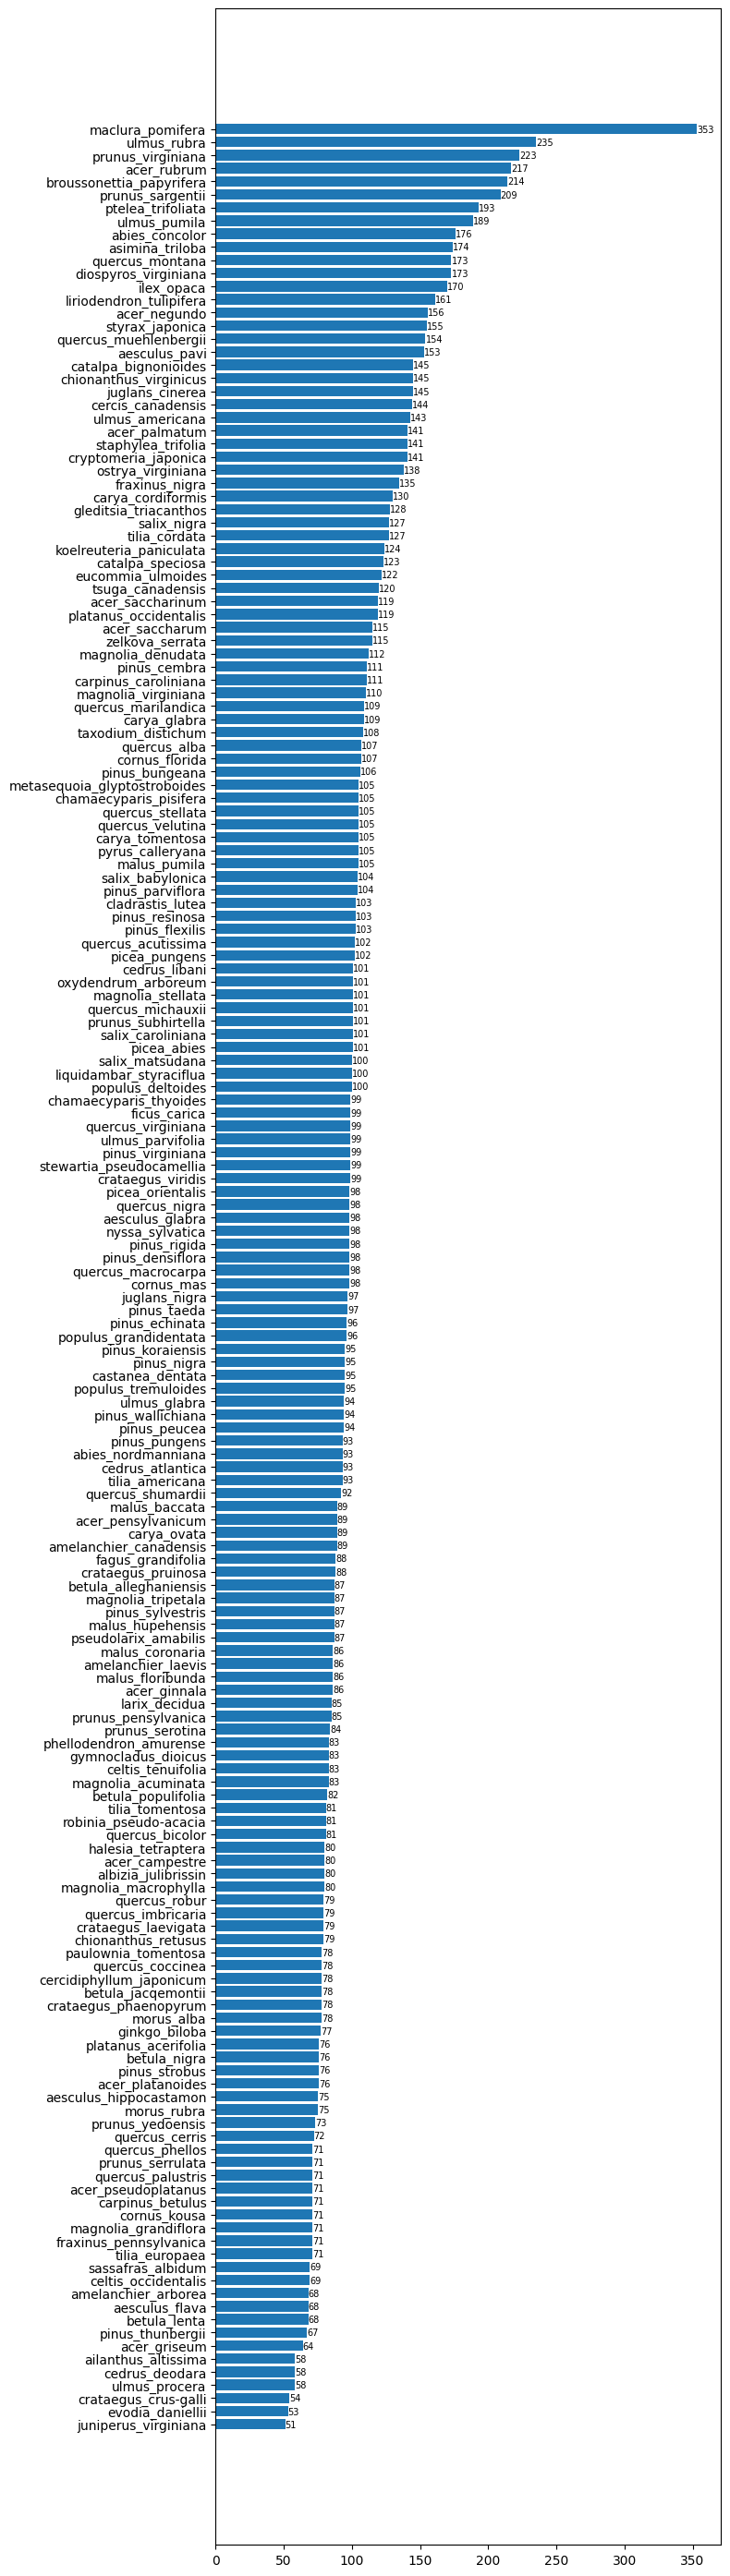

In [4]:
# 各类别样本数的横向条形图（原版用 seaborn.countplot，这里用 matplotlib 等价替代）
def barh(ax):
    for p in ax.patches:
        val = p.get_width()
        y = p.get_y() + p.get_height() / 2
        ax.annotate(int(val), (val, y), va='center', ha='left', fontsize=7)

sorted_counts = sorted(label_counts.items(), key=lambda kv: kv[1])
labels_sorted = [x[0] for x in sorted_counts]
counts_sorted = [x[1] for x in sorted_counts]

fig, ax = plt.subplots(figsize=(8, 28))
ax.barh(labels_sorted, counts_sorted)
barh(ax)
plt.tight_layout()
plt.show()

In [5]:
# 把 label 排个序
leaves_labels = sorted(list(set(label_counts.keys())))
n_classes = len(leaves_labels)
print(n_classes)
leaves_labels[:10]

176


['abies_concolor',
 'abies_nordmanniana',
 'acer_campestre',
 'acer_ginnala',
 'acer_griseum',
 'acer_negundo',
 'acer_palmatum',
 'acer_pensylvanicum',
 'acer_platanoides',
 'acer_pseudoplatanus']

In [6]:
# 把 label 转成对应的数字
class_to_num = dict(zip(leaves_labels, range(n_classes)))
class_to_num

{'abies_concolor': 0,
 'abies_nordmanniana': 1,
 'acer_campestre': 2,
 'acer_ginnala': 3,
 'acer_griseum': 4,
 'acer_negundo': 5,
 'acer_palmatum': 6,
 'acer_pensylvanicum': 7,
 'acer_platanoides': 8,
 'acer_pseudoplatanus': 9,
 'acer_rubrum': 10,
 'acer_saccharinum': 11,
 'acer_saccharum': 12,
 'aesculus_flava': 13,
 'aesculus_glabra': 14,
 'aesculus_hippocastamon': 15,
 'aesculus_pavi': 16,
 'ailanthus_altissima': 17,
 'albizia_julibrissin': 18,
 'amelanchier_arborea': 19,
 'amelanchier_canadensis': 20,
 'amelanchier_laevis': 21,
 'asimina_triloba': 22,
 'betula_alleghaniensis': 23,
 'betula_jacqemontii': 24,
 'betula_lenta': 25,
 'betula_nigra': 26,
 'betula_populifolia': 27,
 'broussonettia_papyrifera': 28,
 'carpinus_betulus': 29,
 'carpinus_caroliniana': 30,
 'carya_cordiformis': 31,
 'carya_glabra': 32,
 'carya_ovata': 33,
 'carya_tomentosa': 34,
 'castanea_dentata': 35,
 'catalpa_bignonioides': 36,
 'catalpa_speciosa': 37,
 'cedrus_atlantica': 38,
 'cedrus_deodara': 39,
 'cedru

In [7]:
# 再转换回来，方便最后预测的时候使用
num_to_class = {v: k for k, v in class_to_num.items()}

In [8]:
# 继承 pytorch 的 dataset，创建自己的（思路与原版完全一致，仅把 pandas 读 csv 换成标准库 csv）
class LeavesData(Dataset):
    def __init__(self, csv_path, file_path, mode='train', valid_ratio=0.2, resize_height=256, resize_width=256):
        """
        Args:
            csv_path (string): csv 文件路径
            file_path (string): 图像文件所在路径
            mode (string): 训练模式还是测试模式
            valid_ratio (float): 验证集比例
        """
        self.file_path = file_path
        self.mode = mode

        # 读取 csv（rows[0] 是表头，语义等价于原版 header=None + iloc[1:]，保证 train/valid 划分一致）
        with open(csv_path, 'r') as f:
            rows = list(csv.reader(f))
        self.data_len = len(rows) - 1
        self.train_len = int(self.data_len * (1 - valid_ratio))

        if mode == 'train':
            self.image_arr = np.asarray([r[0] for r in rows[1:self.train_len]])
            self.label_arr = np.asarray([r[1] for r in rows[1:self.train_len]])
        elif mode == 'valid':
            self.image_arr = np.asarray([r[0] for r in rows[self.train_len:]])
            self.label_arr = np.asarray([r[1] for r in rows[self.train_len:]])
        elif mode == 'test':
            self.image_arr = np.asarray([r[0] for r in rows[1:]])

        self.real_len = len(self.image_arr)
        print('Finished reading the {} set of Leaves Dataset ({} samples found)'
              .format(mode, self.real_len))

    def __getitem__(self, index):
        single_image_name = self.image_arr[index]
        img_as_img = Image.open(self.file_path + single_image_name)

        if self.mode == 'train':
            transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.ToTensor()
            ])
        else:
            # valid 和 test 不做数据增强
            transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor()
            ])

        img_as_img = transform(img_as_img)

        if self.mode == 'test':
            return img_as_img
        else:
            label = self.label_arr[index]
            number_label = class_to_num[label]
            return img_as_img, number_label

    def __len__(self):
        return self.real_len

In [9]:
train_path = 'train.csv'
test_path = 'test.csv'
# 本机 train.csv/test.csv 里 image 列已经带了 images/ 前缀，所以这里只指到当前目录
img_path = './'

train_dataset = LeavesData(train_path, img_path, mode='train')
val_dataset = LeavesData(train_path, img_path, mode='valid')
test_dataset = LeavesData(test_path, img_path, mode='test')
print(train_dataset)
print(val_dataset)
print(test_dataset)

Finished reading the train set of Leaves Dataset (14681 samples found)
Finished reading the valid set of Leaves Dataset (3672 samples found)
Finished reading the test set of Leaves Dataset (8800 samples found)


In [10]:
# 定义 data loader
train_loader = torch.utils.data.DataLoader(
        dataset=train_dataset,
        batch_size=8,
        shuffle=False,
        # Windows 下多进程加载易触发 spawn 报错，batch 很小用 0 足够
        num_workers=0
    )

val_loader = torch.utils.data.DataLoader(
        dataset=val_dataset,
        batch_size=8,
        shuffle=False,
        # Windows 下多进程加载易触发 spawn 报错，batch 很小用 0 足够
        num_workers=0
    )
test_loader = torch.utils.data.DataLoader(
        dataset=test_dataset,
        batch_size=8,
        shuffle=False,
        # Windows 下多进程加载易触发 spawn 报错，batch 很小用 0 足够
        num_workers=0
    )

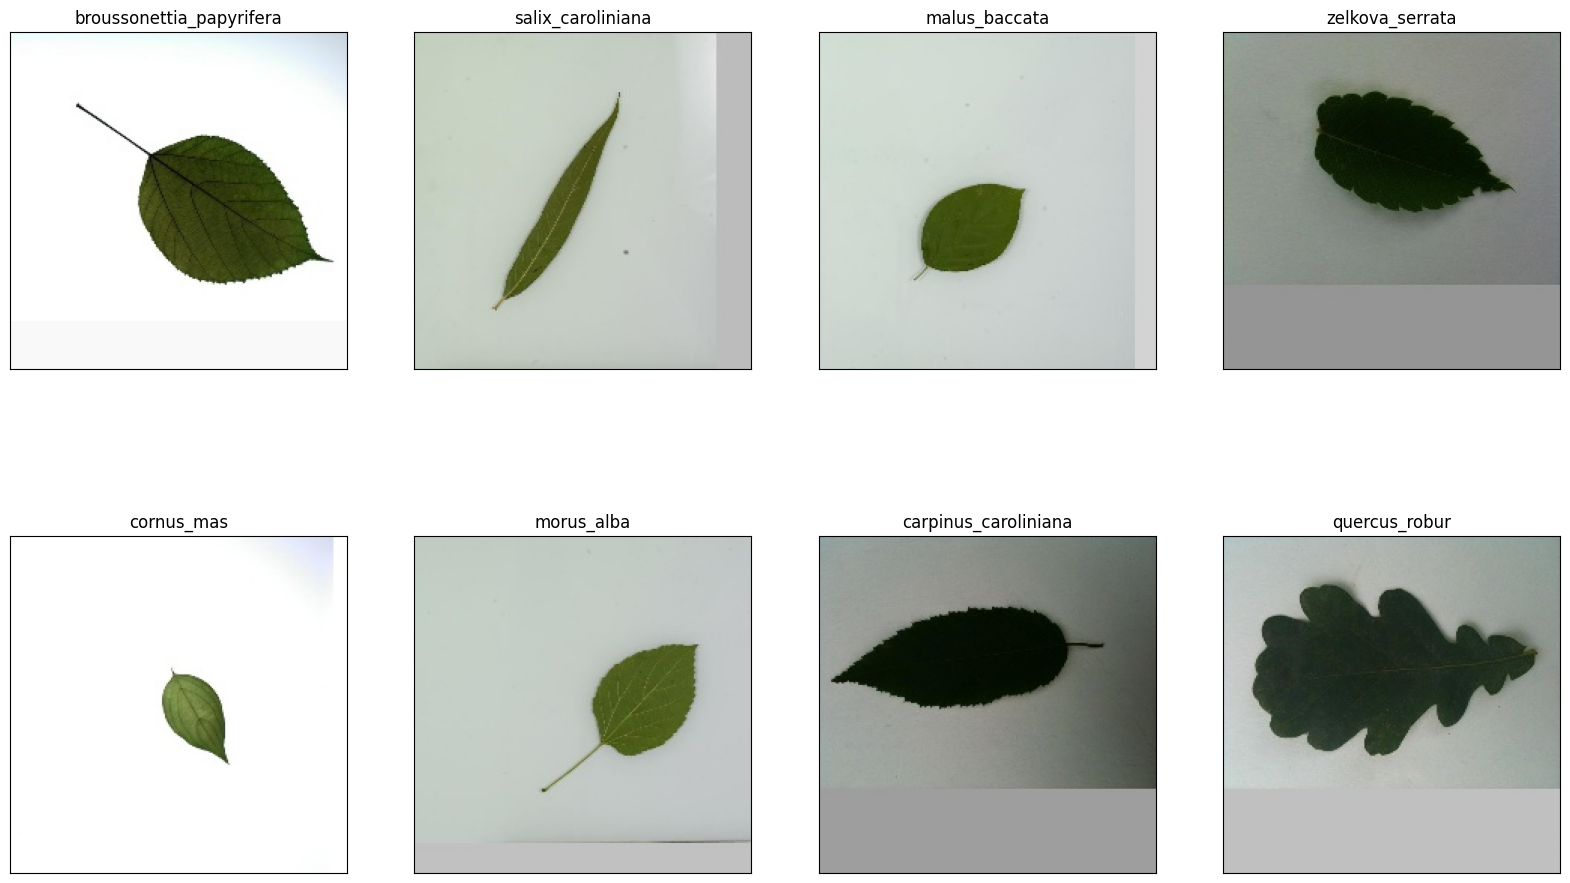

In [11]:
# 给大家展示一下数据长啥样
def im_convert(tensor):
    """ 展示数据"""
    image = tensor.to("cpu").clone().detach()
    image = image.numpy().squeeze()
    image = image.transpose(1, 2, 0)
    image = image.clip(0, 1)
    return image

fig = plt.figure(figsize=(20, 12))
columns = 4
rows = 2

dataiter = iter(val_loader)
inputs, classes = next(dataiter)   # 原版 dataiter.next() 在 Python3 不存在，必须用 next()

for idx in range(columns * rows):
    ax = fig.add_subplot(rows, columns, idx + 1, xticks=[], yticks=[])
    ax.set_title(num_to_class[int(classes[idx])])
    plt.imshow(im_convert(inputs[idx]))
plt.show()

In [12]:
# 看一下是在 cpu 还是 GPU 上
def get_device():
    return 'cuda' if torch.cuda.is_available() else 'cpu'

device = get_device()
print(device)

cuda


In [13]:
# 是否要冻住模型的前面一些层
def set_parameter_requires_grad(model, feature_extracting):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

# resnet34 模型（torchvision 0.28+ 已移除 pretrained=，改用 weights=）
def res_model(num_classes, feature_extract=False, use_pretrained=True):
    weights = models.ResNet34_Weights.IMAGENET1K_V1 if use_pretrained else None
    model_ft = models.resnet34(weights=weights)
    set_parameter_requires_grad(model_ft, feature_extract)
    num_ftrs = model_ft.fc.in_features
    model_ft.fc = nn.Sequential(nn.Linear(num_ftrs, num_classes))
    return model_ft

In [14]:
# 超参数
learning_rate = 3e-4
weight_decay = 1e-3
num_epoch = 50
model_path = './pre_res_model.ckpt'

In [15]:
# 初始化模型并放到设备上
model = res_model(176)
model = model.to(device)
model.device = device
# 分类任务用交叉熵
criterion = nn.CrossEntropyLoss()

# 优化器
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

n_epochs = num_epoch

best_acc = 0.0
for epoch in range(n_epochs):
    # ---------- Training ----------
    model.train()
    train_loss = []
    train_accs = []
    for batch in tqdm(train_loader):
        imgs, labels = batch
        imgs = imgs.to(device)
        labels = labels.to(device)
        logits = model(imgs)
        loss = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        acc = (logits.argmax(dim=-1) == labels).float().mean()
        train_loss.append(loss.item())
        train_accs.append(acc)

    train_loss = sum(train_loss) / len(train_loss)
    train_acc = sum(train_accs) / len(train_accs)
    print(f"[ Train | {epoch + 1:03d}/{n_epochs:03d} ] loss = {train_loss:.5f}, acc = {train_acc:.5f}")

    # ---------- Validation ----------
    model.eval()
    valid_loss = []
    valid_accs = []
    for batch in tqdm(val_loader):
        imgs, labels = batch
        with torch.no_grad():
            logits = model(imgs.to(device))
        loss = criterion(logits, labels.to(device))
        acc = (logits.argmax(dim=-1) == labels.to(device)).float().mean()
        valid_loss.append(loss.item())
        valid_accs.append(acc)

    valid_loss = sum(valid_loss) / len(valid_loss)
    valid_acc = sum(valid_accs) / len(valid_accs)
    print(f"[ Valid | {epoch + 1:03d}/{n_epochs:03d} ] loss = {valid_loss:.5f}, acc = {valid_acc:.5f}")

    # 验证集提升则保存 checkpoint
    if valid_acc > best_acc:
        best_acc = valid_acc
        torch.save(model.state_dict(), model_path)
        print('saving model with acc {:.3f}'.format(best_acc))

100%|██████████| 1836/1836 [01:26<00:00, 21.18it/s]


[ Train | 001/050 ] loss = 2.90058, acc = 0.29262


100%|██████████| 459/459 [00:09<00:00, 46.46it/s]


[ Valid | 001/050 ] loss = 2.14616, acc = 0.41231
saving model with acc 0.412


100%|██████████| 1836/1836 [01:35<00:00, 19.25it/s]


...

[ Valid | 049/050 ] loss = 0.99922, acc = 0.72032


100%|██████████| 1836/1836 [01:45<00:00, 17.48it/s]


[ Train | 050/050 ] loss = 0.20230, acc = 0.95718


100%|██████████| 459/459 [00:11<00:00, 41.66it/s]

[ Valid | 050/050 ] loss = 0.69400, acc = 0.81400


In [16]:
saveFileName = './submission.csv'

In [17]:
## predict
model = res_model(176)
model = model.to(device)
model.load_state_dict(torch.load(model_path))

# 推理模式（关掉 Dropout / BatchNorm 的 train 行为）
model.eval()

predictions = []
for batch in tqdm(test_loader):
    imgs = batch
    with torch.no_grad():
        logits = model(imgs.to(device))
    predictions.extend(logits.argmax(dim=-1).cpu().numpy().tolist())

preds = [num_to_class[i] for i in predictions]

# 用标准库 csv 写 submission（原版用 pandas，这里避开冲突）
with open(test_path, 'r') as f:
    test_rows = list(csv.reader(f))
with open(saveFileName, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['image', 'label'])
    for row, p in zip(test_rows[1:], preds):
        w.writerow([row[0], p])
print("Done!!!!!!!!!!!!!!!!!!!!!!!!!!!")

100%|██████████| 1100/1100 [00:27<00:00, 39.62it/s]


Done!!!!!!!!!!!!!!!!!!!!!!!!!!!


如果觉得有用请给个 vote 😄